# ODIR-5K: per-eye 8-label classification (N, D, G, C, A, H, M, O)
### EfficientNet-B0 · 512px · multi-label (sigmoid + BCE) · same patient-grouped test set as the binary models

Each eye gets **8 independent yes/no predictions**. An eye can have several diseases, for example diabetic retinopathy plus a laser scar ("Other").

| | Category | Built from this eye's keywords |
|---|---|---|
| N | Normal | only `normal fundus` (artifacts such as `lens dust` ignored) |
| D | Diabetic retinopathy | mild / moderate / severe non-proliferative, proliferative |
| G | Glaucoma | glaucoma, suspected glaucoma |
| C | Cataract | cataract |
| A | AMD | dry / wet age-related macular degeneration |
| H | Hypertension | hypertensive retinopathy |
| M | Myopia | pathological myopia, myopic retinopathy or maculopathy |
| O | Other | every other diagnostic keyword (epiretinal membrane, drusen, laser spot, …) |

**How to run.** Put the notebook in the same folder as before; it writes to `outputs_ml/`.
1. **First run** with `FOLDS_TO_RUN = [0]`: one model, about 20–25 minutes on the V100. Check the per-class results.
2. **Then** set `FOLDS_TO_RUN = [0, 1, 2, 3, 4]` and run again. Fold 0 is skipped because it is already trained, and the results become the 5-model ensemble with mean ± sd across folds.

```bash
export CUDA_DEVICE_ORDER=PCI_BUS_ID CUDA_VISIBLE_DEVICES=0 PYTHONUNBUFFERED=1
jupyter nbconvert --to notebook --execute odir_multilabel_8class.ipynb --output ml_run.ipynb \
    --ExecutePreprocessor.timeout=-1 --ExecutePreprocessor.kernel_name=odir-env
```

## 1. Setup

In [1]:
import os, re, gc, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             f1_score, cohen_kappa_score)

warnings.filterwarnings('ignore')

In [2]:
# ----------------------------- Config -----------------------------
DATASET  = 'andrewmvd/ocular-disease-recognition-odir5k'
DATA_DIR = Path('/kaggle/input/ocular-disease-recognition-odir5k')   # or the folder containing full_df.csv
OUT_DIR  = Path('/kaggle/working/outputs_ml') if Path('/kaggle/working').exists() else Path('outputs_ml')

FOLDS_TO_RUN = [0, 1, 2, 3, 4]      # first run: [0]  ->  final run: [0, 1, 2, 3, 4]
N_FOLDS      = 5
IMG_SIZE     = 512
BATCH_SIZE   = 32       # 16 if you get CUDA out-of-memory
NUM_WORKERS  = 0 if os.name == 'nt' else min(4, os.cpu_count() or 2)
SEED         = 42

FROZEN_EPOCHS, FINETUNE_EPOCHS, PATIENCE = 3, 30, 7
LR_HEAD, LR_BACKBONE, WEIGHT_DECAY = 1e-3, 1e-4, 0.05
DROPOUT, MIXUP_ALPHA, MIXUP_PROB = 0.5, 0.4, 0.5
POS_WEIGHT_CAP = 10.0   # pos_weight = sqrt(neg/pos), capped: helps rare classes (H, A, M) without overshooting

CLASSES = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']
NAMES   = {'N': 'Normal', 'D': 'Diabetic retinopathy', 'G': 'Glaucoma', 'C': 'Cataract',
           'A': 'AMD', 'H': 'Hypertension', 'M': 'Myopia', 'O': 'Other'}

In [3]:
def find_dataset():
    if (DATA_DIR / 'full_df.csv').exists():
        return DATA_DIR
    root = Path('/kaggle/input')
    hits = sorted(root.rglob('full_df.csv')) if root.exists() else []
    if hits:
        return hits[0].parent
    print(f'Dataset not found locally - fetching {DATASET} with kagglehub ...')
    try:
        import kagglehub
        path = Path(kagglehub.dataset_download(DATASET))
    except Exception as e:
        raise RuntimeError(f'Could not fetch {DATASET}. Turn on Internet / set up kaggle.json, or set DATA_DIR.') from e
    hits = sorted(path.rglob('full_df.csv'))
    if not hits:
        raise FileNotFoundError(f'full_df.csv not found in {path}')
    return hits[0].parent

DATA_DIR = find_dataset()
CSV_PATH, IMG_DIR = DATA_DIR / 'full_df.csv', DATA_DIR / 'preprocessed_images'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(SEED)
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
torch.backends.cudnn.benchmark = True
if USE_AMP:
    try:
        torch.ones(1, device=device).add_(1); torch.cuda.synchronize()
    except RuntimeError as e:
        raise RuntimeError(f'PyTorch {torch.__version__} cannot run on {torch.cuda.get_device_name(0)}.') from e
print('torch', torch.__version__, '| device:', device, f'({torch.cuda.get_device_name(0)})' if USE_AMP else '- NO GPU')
print('data :', DATA_DIR); print('out  :', OUT_DIR.resolve()); print('folds to run:', FOLDS_TO_RUN)

Dataset not found locally - fetching andrewmvd/ocular-disease-recognition-odir5k with kagglehub ...


torch 2.14.0+cu126 | device: cuda (Tesla V100-PCIE-32GB)
data : /home/utkarsh/.cache/kagglehub/datasets/andrewmvd/ocular-disease-recognition-odir5k/versions/2
out  : /home/utkarsh/Desktop/utkarsh/utkarsh_image/outputs_ml
folds to run: [0, 1, 2, 3, 4]


## 2. Per-eye 8-label targets

The labelling follows the same rules as the binary model: each eye's own keywords, artifacts ignored, unusable images dropped. Each diagnostic keyword is then mapped to one category, and anything not matched goes to **O (Other)**.

**Mapping check.** For patients with both eyes labelled, combining the two eyes should reproduce ODIR's official patient-level columns: a disease is present if either eye has it, and N only if both eyes are normal. The table shows how often the two agree. For any disagreement it lists the keywords involved, so the mapping can be corrected.

In [4]:
raw = pd.read_csv(CSV_PATH)
patients = raw.drop_duplicates(subset='ID').reset_index(drop=True)

UNUSABLE  = {'low image quality', 'no fundus image', 'anterior segment image'}
ARTIFACTS = {'lens dust', 'image offset', 'optic disk photographically invisible'}
CATEGORY_RULES = [('D', r'proliferative|diabetic retinopathy'), ('G', r'glaucoma'), ('C', r'cataract'),
                  ('A', r'age-related macular degeneration'), ('H', r'hypertensive retinopathy'), ('M', r'myopi')]

def split_keywords(text):
    if pd.isna(text):
        return []
    return [t.strip() for t in re.split(r'[，,、;；]', str(text).lower()) if t.strip()]

def term_category(term):
    return next((c for c, rx in CATEGORY_RULES if re.search(rx, term)), 'O')

def eye_labels(keywords):
    """dict of 8 binary labels, or None to drop the image."""
    terms = set(split_keywords(keywords))
    if terms & UNUSABLE:
        return None
    diagnoses = terms - ARTIFACTS
    if not diagnoses:
        return None
    y = dict.fromkeys(CLASSES, 0)
    if diagnoses == {'normal fundus'}:
        y['N'] = 1
    else:
        for t in diagnoses - {'normal fundus'}:
            y[term_category(t)] = 1
    return y

rows = []
for _, r in patients.iterrows():
    for side in ('Left', 'Right'):
        path = IMG_DIR / r[f'{side}-Fundus']
        y = eye_labels(r[f'{side}-Diagnostic Keywords'])
        if path.exists() and y is not None:
            rows.append({'ID': r['ID'], 'eye': side.lower(), 'file_path': str(path),
                         'keywords': ', '.join(split_keywords(r[f'{side}-Diagnostic Keywords'])), **y})
eyes = pd.DataFrame(rows)
eyes['target'] = 1 - eyes['N']                       # abnormal - used for the (unchanged) split
counts = eyes[CLASSES].sum()
print(f'{len(eyes)} labelled eyes from {eyes.ID.nunique()} patients | eyes with 2+ diseases: {(eyes[CLASSES[1:]].sum(1) >= 2).mean():.1%}')
display(pd.DataFrame({'category': [NAMES[c] for c in CLASSES], 'eyes': counts.values,
                      'share': (counts.values / len(eyes) * 100).round(1)}, index=CLASSES))

6391 labelled eyes from 3357 patients | eyes with 2+ diseases: 6.5%


,category,eyes,share
N,Normal,2873,45.0
D,Diabetic retinopathy,1722,26.9
G,Glaucoma,313,4.9
C,Cataract,301,4.7
A,AMD,279,4.4
H,Hypertension,192,3.0
M,Myopia,256,4.0
O,Other,879,13.8


In [5]:
# Mapping check against ODIR's official patient-level columns (patients with both eyes labelled)
both = eyes.groupby('ID').filter(lambda g: len(g) == 2)
pat = both.groupby('ID')[CLASSES].max()
pat['N'] = both.groupby('ID')['N'].min()
truth = patients.set_index('ID').loc[pat.index, CLASSES].astype(int)
agree = (pat == truth).mean()
print(f'{len(pat)} patients with both eyes labelled')
display(pd.DataFrame({'agreement': (agree * 100).round(1).astype(str) + '%',
                      'ours=1, ODIR=0': ((pat == 1) & (truth == 0)).sum(),
                      'ours=0, ODIR=1': ((pat == 0) & (truth == 1)).sum()}).T)

kw_of = both.groupby('ID')['keywords'].apply(lambda s: ', '.join(s))
for c in CLASSES[1:]:
    bad = pat.index[pat[c] != truth[c]]
    if len(bad):
        terms = pd.Series([t for k in kw_of.loc[bad] for t in split_keywords(k) if t not in ARTIFACTS and t != 'normal fundus'])
        print(f'{c} ({NAMES[c]}): {len(bad)} disagreements; most common keywords there:',
              dict(terms.value_counts().head(6)))
print('\nKeywords mapped to O (Other):', dict(pd.Series([t for k in eyes['keywords'] for t in split_keywords(k)
      if t not in ARTIFACTS and t != 'normal fundus' and term_category(t) == 'O']).value_counts().head(25)))

3034 patients with both eyes labelled


,N,D,G,C,A,H,M,O
agreement,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
"ours=1, ODIR=0",0,0,0,0,0,0,0,0
"ours=0, ODIR=1",0,0,0,0,0,0,0,0



Keywords mapped to O (Other): {'macular epiretinal membrane': np.int64(189), 'epiretinal membrane': np.int64(171), 'drusen': np.int64(170), 'myelinated nerve fibers': np.int64(92), 'vitreous degeneration': np.int64(69), 'refractive media opacity': np.int64(63), 'laser spot': np.int64(39), 'maculopathy': np.int64(26), 'branch retinal vein occlusion': np.int64(25), 'epiretinal membrane over the macula': np.int64(14), 'post laser photocoagulation': np.int64(6), 'white vessel': np.int64(6), 'old branch retinal vein occlusion': np.int64(6), 'atrophic change': np.int64(4), 'optic nerve atrophy': np.int64(3), 'spotted membranous change': np.int64(3), 'abnormal pigment': np.int64(2), 'chorioretinal atrophy': np.int64(2), 'old central retinal vein occlusion': np.int64(2), 'optic disc edema': np.int64(2), 'vessel tortuosity': np.int64(2), 'intraretinal hemorrhage': np.int64(2), 'optic disk epiretinal membrane': np.int64(1), 'retina fold': np.int64(1), 'retinitis pigmentosa': np.int64(1)}


## 3. Split (identical to the binary models) and folds

In [6]:
def group_split(df, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    keep_idx, hold_idx = next(sgkf.split(df, df['target'], groups=df['ID']))
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[hold_idx].reset_index(drop=True)

trainval_df, test_df = group_split(eyes, 5, SEED)          # same test patients as v1 / v2 / binary CV
trainval_df['fold'] = -1
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for k, (_, va_idx) in enumerate(sgkf.split(trainval_df, trainval_df['target'], groups=trainval_df['ID'])):
    trainval_df.loc[va_idx, 'fold'] = k
assert trainval_df.groupby('ID').fold.nunique().max() == 1 and not set(trainval_df.ID) & set(test_df.ID)

prev = pd.concat({f'fold {k}': trainval_df[trainval_df.fold == k][CLASSES].sum() for k in range(N_FOLDS)}, axis=1)
prev['test'] = test_df[CLASSES].sum()
print(f'test: {len(test_df)} images, {test_df.ID.nunique()} patients  -  positive eyes per class:')
display(prev.T)

test: 1281 images, 671 patients  -  positive eyes per class:


,N,D,G,C,A,H,M,O
fold 0,484,246,42,52,34,33,38,147
fold 1,454,292,55,51,48,33,46,137
fold 2,456,280,49,41,63,30,41,123
fold 3,455,271,45,47,48,32,40,143
fold 4,455,278,55,50,42,30,39,148
test,569,355,67,60,44,34,52,181


## 4. Data, model and training functions

In [7]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tfms = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(30),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.03),
    T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.25, scale=(0.02, 0.08)),
])
eval_tfms = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

class FundusDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df['file_path'].tolist()
        self.y = torch.tensor(df[CLASSES].values, dtype=torch.float32)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert('RGB')), self.y[i]

def make_loader(df, tfms, shuffle):
    return DataLoader(FundusDataset(df, tfms), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=USE_AMP, drop_last=shuffle, persistent_workers=NUM_WORKERS > 0)

def build_model(pretrained=True):
    try:
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
    except Exception as e:
        raise RuntimeError('Could not download the ImageNet weights - check Internet access.') from e
    model.classifier = nn.Sequential(nn.Dropout(p=DROPOUT), nn.Linear(model.classifier[1].in_features, len(CLASSES)))
    return model.to(device)

def set_backbone_trainable(model, trainable):
    for p in model.features.parameters():
        p.requires_grad = trainable

def macro_auc(y, p):
    """Mean ROC-AUC over classes that have both positives and negatives."""
    aucs = [roc_auc_score(y[:, j], p[:, j]) for j in range(y.shape[1]) if 0 < y[:, j].sum() < len(y)]
    return float(np.mean(aucs)) if aucs else float('nan')

def run_epoch(model, loader, criterion, scaler, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training and not next(model.features.parameters()).requires_grad:
        model.features.eval()
    total, probs, targets = 0.0, [], []
    for x, y in tqdm(loader, leave=False, desc='train' if training else 'eval'):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        y_true = y
        if training and MIXUP_ALPHA > 0 and np.random.rand() < MIXUP_PROB:
            lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)); lam = max(lam, 1 - lam)
            perm = torch.randperm(x.size(0), device=x.device)
            x, y = lam * x + (1 - lam) * x[perm], lam * y + (1 - lam) * y[perm]   # soft multi-label targets
        with torch.set_grad_enabled(training), torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits.float(), y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        total += loss.item() * x.size(0)
        probs.append(torch.sigmoid(logits.float()).detach().cpu()); targets.append(y_true.cpu())
    probs, targets = torch.cat(probs).numpy(), torch.cat(targets).numpy()
    return total / len(probs), macro_auc(targets, probs)

@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); out = []
    for x, _ in tqdm(loader, leave=False, desc='predict'):
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            p = (torch.sigmoid(model(x).float()) + torch.sigmoid(model(torch.flip(x, dims=[3])).float())) / 2
        out.append(p.float().cpu())
    return torch.cat(out).numpy()

test_loader = make_loader(test_df, eval_tfms, shuffle=False)
P_COLS = [f'p_{c}' for c in CLASSES]

In [8]:
def train_fold(k):
    ckpt, val_file, test_file = OUT_DIR / f'fold{k}_best.pt', OUT_DIR / f'fold{k}_val_preds.csv', OUT_DIR / f'fold{k}_test_preds.csv'
    if ckpt.exists() and val_file.exists() and test_file.exists():
        print(f'fold {k}: already done - skipping'); return
    seed_everything(SEED + k)
    tr_df, va_df = trainval_df[trainval_df.fold != k], trainval_df[trainval_df.fold == k]
    train_loader, val_loader = make_loader(tr_df, train_tfms, True), make_loader(va_df, eval_tfms, False)
    model = build_model()
    pos = tr_df[CLASSES].sum().values.astype(float); neg = len(tr_df) - pos
    pos_weight = torch.tensor(np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1.0, POS_WEIGHT_CAP), dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    state, history = dict(auc=-1.0, loss=float('inf'), epoch=0, bad=0), []
    print(f'===== fold {k}: {len(tr_df)} train / {len(va_df)} val | pos_weight', dict(zip(CLASSES, pos_weight.cpu().numpy().round(2))))

    def fit(optimizer, scheduler, n_epochs, stage):
        for _ in range(n_epochs):
            t0 = time.time()
            tr_loss, tr_auc = run_epoch(model, train_loader, criterion, scaler, optimizer)
            va_loss, va_auc = run_epoch(model, val_loader, criterion, scaler)
            if scheduler is not None:
                scheduler.step()
            epoch = len(history) + 1
            history.append(dict(epoch=epoch, stage=stage, train_loss=tr_loss, val_loss=va_loss, train_auc=tr_auc, val_auc=va_auc))
            improved = va_auc > state['auc'] or (va_auc == state['auc'] and va_loss < state['loss'])
            if improved:
                state.update(auc=va_auc, loss=va_loss, epoch=epoch, bad=0); torch.save(model.state_dict(), ckpt)
            else:
                state['bad'] += 1
            print(f'[fold {k} {stage:8s}] epoch {epoch:2d} | train loss {tr_loss:.4f} macro-AUC {tr_auc:.4f} | '
                  f'val loss {va_loss:.4f} macro-AUC {va_auc:.4f} | {time.time() - t0:4.0f}s' + ('  <- best' if improved else ''))
            if stage == 'finetune' and state['bad'] >= PATIENCE:
                print(f'fold {k}: early stopping'); break

    set_backbone_trainable(model, False)
    fit(torch.optim.AdamW(model.classifier.parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY), None, FROZEN_EPOCHS, 'frozen')
    set_backbone_trainable(model, True)
    opt = torch.optim.AdamW([{'params': model.features.parameters(), 'lr': LR_BACKBONE},
                             {'params': model.classifier.parameters(), 'lr': LR_HEAD}], weight_decay=WEIGHT_DECAY)
    state['bad'] = 0
    fit(opt, torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FINETUNE_EPOCHS, eta_min=1e-6), FINETUNE_EPOCHS, 'finetune')
    print(f'fold {k}: best val macro-AUC {state["auc"]:.4f} at epoch {state["epoch"]}')

    model.load_state_dict(torch.load(ckpt, map_location=device))
    pd.DataFrame(history).to_csv(OUT_DIR / f'fold{k}_history.csv', index=False)
    for df_, loader, f in [(va_df, val_loader, val_file), (test_df, test_loader, test_file)]:
        out = df_[['ID', 'eye', 'file_path'] + CLASSES].copy()
        out[P_COLS] = predict_probs(model, loader)
        out.to_csv(f, index=False)
    del model, train_loader, val_loader; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()

## 5. Train

In [9]:
t_start = time.time()
for k in FOLDS_TO_RUN:
    train_fold(k)
print(f'Done in {(time.time() - t_start) / 3600:.2f} h')

fold 0: already done - skipping


===== fold 1: 4078 train / 1032 val | pos_weight {'N': np.float32(1.1), 'D': np.float32(1.67), 'G': np.float32(4.51), 'C': np.float32(4.52), 'A': np.float32(4.56), 'H': np.float32(5.62), 'M': np.float32(4.98), 'O': np.float32(2.5)}


train:   0%|          | 0/127 [00:00<?, ?it/s]

eval:   0%|          | 0/33 [00:00<?, ?it/s]

[fold 1 frozen  ] epoch  1 | train loss 0.5511 macro-AUC 0.6796 | val loss 0.5038 macro-AUC 0.7701 |   50s  <- best


...

eval:   0%|          | 0/32 [00:00<?, ?it/s]

[fold 4 finetune] epoch 19 | train loss 0.2817 macro-AUC 0.9466 | val loss 0.3647 macro-AUC 0.8923 |   41s
fold 4: early stopping
fold 4: best val macro-AUC 0.8956 at epoch 12


predict:   0%|          | 0/32 [00:00<?, ?it/s]

predict:   0%|          | 0/41 [00:00<?, ?it/s]

Done in 1.32 h


## 6. Results on the test set

- **Folds used:** every fold with saved predictions. With only fold 0 this is a single model; with all five it is the 5-model ensemble.
- **Per-class thresholds:** chosen on the pooled out-of-fold validation predictions to maximise that class's F1, and never tuned on test.
- **AUC intervals:** 95% CIs from 1,000 patient-level bootstrap resamples.

In [10]:
done = [k for k in range(N_FOLDS) if (OUT_DIR / f'fold{k}_test_preds.csv').exists()]
val_preds  = [pd.read_csv(OUT_DIR / f'fold{k}_val_preds.csv') for k in done]
test_preds = [pd.read_csv(OUT_DIR / f'fold{k}_test_preds.csv') for k in done]
for tp_ in test_preds:
    assert (tp_['file_path'].values == test_df['file_path'].values).all()
Y = test_df[CLASSES].values
P = np.mean([tp_[P_COLS].values for tp_ in test_preds], axis=0)
oof = pd.concat(val_preds, ignore_index=True)
Yv, Pv = oof[CLASSES].values, oof[P_COLS].values
print(f'models in ensemble: {len(done)} (folds {done})')

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return float(thr[np.argmax(f1[:-1])]) if len(thr) else 0.5

THR = {c: best_f1_threshold(Yv[:, j], Pv[:, j]) for j, c in enumerate(CLASSES)}

rng = np.random.default_rng(SEED)
groups = test_df['ID'].values; uniq = np.unique(groups); idx_of = {g: np.flatnonzero(groups == g) for g in uniq}
boot = [np.concatenate([idx_of[g] for g in rng.choice(uniq, size=len(uniq), replace=True)]) for _ in range(1000)]

def auc_ci(y, p):
    vals = [roc_auc_score(y[b], p[b]) for b in boot if 0 < y[b].sum() < len(b)]
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

rows = []
for j, c in enumerate(CLASSES):
    y, p = Y[:, j], P[:, j]; pred = (p >= THR[c]).astype(int)
    ok = 0 < y.sum() < len(y)
    lo, hi = auc_ci(y, p) if ok else (np.nan, np.nan)
    tp, fn, tn, fp = ((pred == 1) & (y == 1)).sum(), ((pred == 0) & (y == 1)).sum(), ((pred == 0) & (y == 0)).sum(), ((pred == 1) & (y == 0)).sum()
    rows.append({'class': c, 'name': NAMES[c], 'test positives': int(y.sum()),
                 'AUC': roc_auc_score(y, p) if ok else np.nan, 'AUC 95% CI': f'{lo:.3f}-{hi:.3f}' if ok else '-',
                 'AP': average_precision_score(y, p) if ok else np.nan, 'threshold': THR[c],
                 'F1': f1_score(y, pred, zero_division=0), 'sensitivity': tp / max(tp + fn, 1), 'specificity': tn / max(tn + fp, 1)})
per_class = pd.DataFrame(rows).set_index('class')
per_class.to_csv(OUT_DIR / 'per_class_test_metrics.csv')

valid = [j for j in range(len(CLASSES)) if 0 < Y[:, j].sum() < len(Y)]
summary = {'macro AUC': np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in valid]),
           'micro AUC': roc_auc_score(Y[:, valid].ravel(), P[:, valid].ravel()),
           'macro F1 (tuned thresholds)': per_class['F1'].mean(),
           'Normal vs abnormal AUC (1 - p_N)': roc_auc_score(1 - Y[:, 0], 1 - P[:, 0])}
for k, v in summary.items():
    print(f'{k:36s} {v:.4f}')
display(per_class.round(3))

models in ensemble: 5 (folds [0, 1, 2, 3, 4])


macro AUC                            0.9319
micro AUC                            0.9547
macro F1 (tuned thresholds)          0.6862
Normal vs abnormal AUC (1 - p_N)     0.8782


,name,test positives,AUC,AUC 95% CI,AP,threshold,F1,sensitivity,specificity
class,,,,,,,,,
N,Normal,569,0.878,0.856-0.897,0.829,0.426,0.791,0.909,0.690
D,Diabetic retinopathy,355,0.903,0.881-0.924,0.844,0.397,0.755,0.713,0.933
G,Glaucoma,67,0.944,0.912-0.971,0.594,0.521,0.607,0.657,0.972
C,Cataract,60,0.983,0.962-0.996,0.841,0.853,0.817,0.817,0.991
A,AMD,44,0.947,0.901-0.982,0.635,0.708,0.625,0.568,0.991
H,Hypertension,34,0.937,0.890-0.975,0.451,0.382,0.424,0.412,0.986
M,Myopia,52,0.996,0.990-1.000,0.964,0.679,0.891,0.865,0.997
O,Other,181,0.867,0.835-0.896,0.650,0.420,0.580,0.613,0.917


In [11]:
# Per-fold spread (only meaningful with 2+ folds)
if len(done) > 1:
    pf = pd.DataFrame([{**{'fold': k}, **{c: roc_auc_score(Y[:, j], tp_[P_COLS].values[:, j]) for j, c in enumerate(CLASSES) if j in valid},
                        'macro': np.mean([roc_auc_score(Y[:, j], tp_[P_COLS].values[:, j]) for j in valid])}
                       for k, tp_ in zip(done, test_preds)]).set_index('fold')
    pf.to_csv(OUT_DIR / 'per_fold_test_auc.csv')
    print('Test AUC per fold model:'); display(pf.round(3))
    print('mean ± sd:', {c: f'{pf[c].mean():.3f} ± {pf[c].std(ddof=1):.3f}' for c in pf.columns})
else:
    print('Single fold so far - run with FOLDS_TO_RUN = [0, 1, 2, 3, 4] for mean ± sd and the ensemble.')

Test AUC per fold model:


,N,D,G,C,A,H,M,O,macro
fold,,,,,,,,,
0,0.862,0.892,0.934,0.976,0.951,0.903,0.996,0.847,0.920
1,0.879,0.903,0.939,0.979,0.925,0.910,0.997,0.866,0.925
2,0.874,0.891,0.931,0.976,0.939,0.900,0.995,0.849,0.919
3,0.874,0.904,0.942,0.982,0.939,0.907,0.995,0.854,0.924
4,0.859,0.886,0.932,0.980,0.930,0.927,0.996,0.832,0.918


mean ± sd: {'N': '0.869 ± 0.008', 'D': '0.895 ± 0.008', 'G': '0.935 ± 0.005', 'C': '0.978 ± 0.003', 'A': '0.937 ± 0.010', 'H': '0.909 ± 0.011', 'M': '0.996 ± 0.001', 'O': '0.850 ± 0.012', 'macro': '0.921 ± 0.003'}


In [12]:
# Official ODIR-style patient-level score: combine both eyes (disease = max over eyes, N = min), threshold 0.5,
# flattened Cohen kappa, micro F1 and micro AUC, final = their mean.  Our own test split, so not comparable to the leaderboard.
te = test_df[['ID']].copy(); te[P_COLS] = P
two = te.groupby('ID').filter(lambda g: len(g) == 2)
pp = two.groupby('ID')[P_COLS].max(); pp['p_N'] = two.groupby('ID')['p_N'].min()
gt = patients.set_index('ID').loc[pp.index, CLASSES].astype(int).values
pr = pp[P_COLS].values
kappa = cohen_kappa_score(gt.ravel(), (pr.ravel() >= 0.5).astype(int))
f1m = f1_score(gt.ravel(), (pr.ravel() >= 0.5).astype(int), average='micro')
aucm = roc_auc_score(gt.ravel(), pr.ravel())
print(f'{len(pp)} test patients with both eyes | kappa {kappa:.4f} | F1 {f1m:.4f} | AUC {aucm:.4f} | final score {(kappa + f1m + aucm) / 3:.4f}')
pd.DataFrame([{'patients': len(pp), 'kappa': kappa, 'f1_micro': f1m, 'auc_micro': aucm, 'final': (kappa + f1m + aucm) / 3}]).to_csv(OUT_DIR / 'odir_patient_score.csv', index=False)

610 test patients with both eyes | kappa 0.6461 | F1 0.9111 | AUC 0.9472 | final score 0.8348

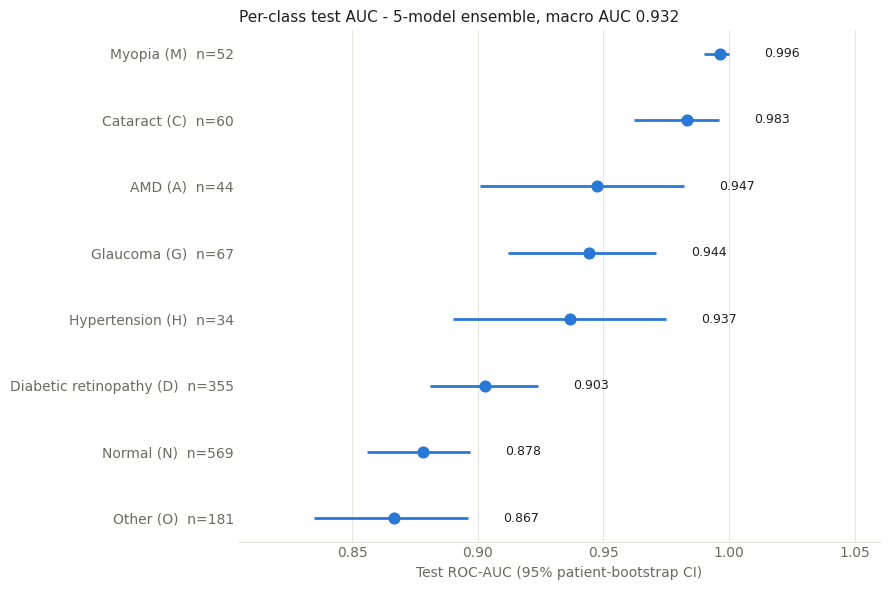

In [13]:
# Per-class test AUC with 95% CI, sorted
INK, MUTED, GRID, ACCENT = '#1f1f1e', '#6b6a64', '#e6e5e0', '#2a78d6'
pc = per_class.dropna(subset=['AUC']).sort_values('AUC')
lo = pc['AUC 95% CI'].str.split('-').str[0].astype(float); hi = pc['AUC 95% CI'].str.split('-').str[1].astype(float)
y = np.arange(len(pc))
fig, ax = plt.subplots(figsize=(9, 0.55 * len(pc) + 1.6))
ax.hlines(y, lo, hi, color=ACCENT, lw=2, zorder=2)
ax.scatter(pc['AUC'], y, s=60, color=ACCENT, zorder=3)
for yi, a, h in zip(y, pc['AUC'], hi):
    ax.text(max(h, a) + 0.014, yi, f'{a:.3f}', va='center', fontsize=9, color=INK)
ax.set_yticks(y, [f'{NAMES[c]} ({c})  n={n}' for c, n in zip(pc.index, pc['test positives'])], fontsize=10, color=INK)
ax.set_xlim(max(0.5, lo.min() - 0.03), 1.06); ax.set_xlabel('Test ROC-AUC (95% patient-bootstrap CI)', color=MUTED)
ax.xaxis.grid(True, color=GRID, zorder=0); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color(GRID); ax.tick_params(colors=MUTED, length=0)
ax.set_title(f'Per-class test AUC - {len(done)}-model {"ensemble" if len(done) > 1 else "(single model)"}, '
             f'macro AUC {summary["macro AUC"]:.3f}', loc='left', fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(OUT_DIR / 'per_class_auc.png', dpi=150); plt.show()

## 7. Grad-CAM per class

For each disease class, the figure shows one test eye that is a true positive: the eye with the median score among the correctly detected ones. Each map targets **that class's logit** and is averaged over the fold models.

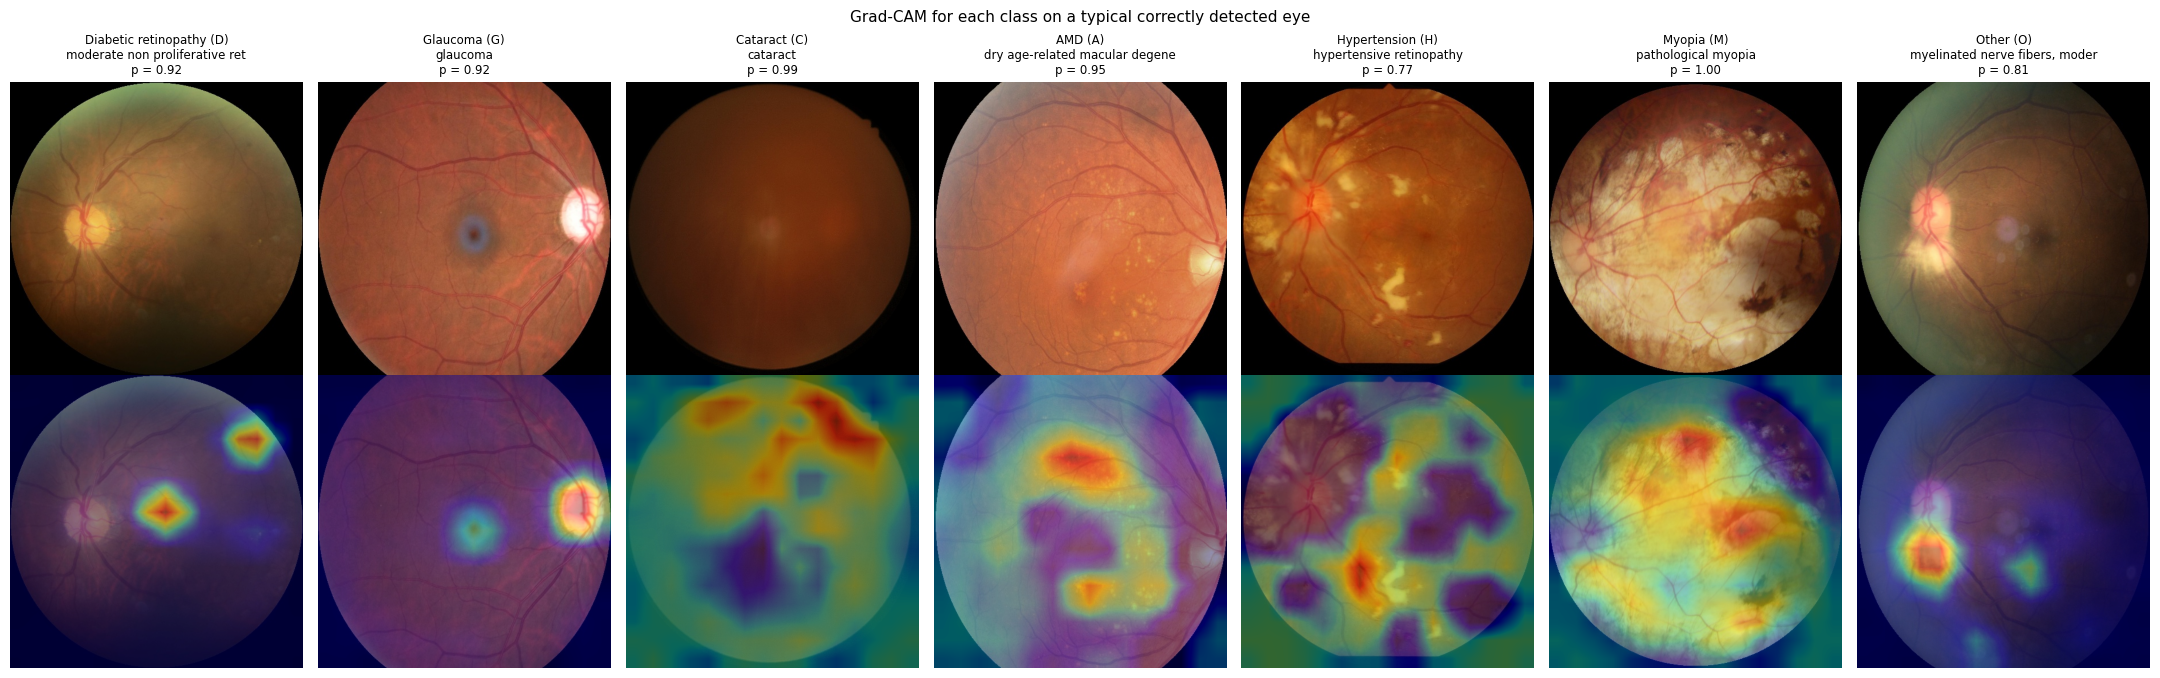

In [14]:
models = []
for k in done:
    m = build_model(pretrained=False); m.load_state_dict(torch.load(OUT_DIR / f'fold{k}_best.pt', map_location=device)); models.append(m.eval())

def denorm(t):
    return (t.permute(1, 2, 0).cpu().numpy() * STD + MEAN).clip(0, 1)

def class_cam(x, j):
    total = torch.zeros(x.size(0), *x.shape[-2:], device=x.device)
    for m in models:
        store = {}
        def hook(module, inp, out):
            store['a'] = out; out.register_hook(lambda g: store.__setitem__('g', g))
        h = m.features[-1].register_forward_hook(hook)
        with torch.enable_grad():
            logits = m(x); m.zero_grad(set_to_none=True); logits[:, j].sum().backward()
        h.remove()
        cam = F.relu((store['g'].mean((2, 3), keepdim=True) * store['a']).sum(1, keepdim=True))
        total += F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0].detach()
    total -= total.amin((1, 2), keepdim=True)
    return (total / (total.amax((1, 2), keepdim=True) + 1e-8)).cpu().numpy()

shown = []
for j, c in enumerate(CLASSES[1:], start=1):
    hit = np.flatnonzero((Y[:, j] == 1) & (P[:, j] >= THR[c]))
    if len(hit):
        i = hit[np.argsort(np.abs(P[hit, j] - np.median(P[hit, j])))[0]]
        shown.append((j, c, i))
if shown:
    fig, axes = plt.subplots(2, len(shown), figsize=(3.1 * len(shown), 7.0), squeeze=False)
    for col, (j, c, i) in enumerate(shown):
        x = eval_tfms(Image.open(test_df.file_path.iloc[i]).convert('RGB')).unsqueeze(0).to(device)
        cam = class_cam(x, j)[0]; img = denorm(x[0])
        axes[0, col].imshow(img); axes[0, col].set_title(f'{NAMES[c]} ({c})\n{test_df.keywords.iloc[i][:30]}\np = {P[i, j]:.2f}', fontsize=8.5)
        axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap='jet', alpha=0.4)
    for a in axes.ravel(): a.axis('off')
    plt.suptitle('Grad-CAM for each class on a typical correctly detected eye', fontsize=11)
    plt.tight_layout(); plt.savefig(OUT_DIR / 'gradcam_per_class.png', dpi=130); plt.show()

In [15]:
# Save the ensemble + thresholds and a predict() helper
torch.save({'state_dicts': [m.state_dict() for m in models], 'thresholds': THR, 'classes': CLASSES, 'names': NAMES,
            'img_size': IMG_SIZE, 'arch': 'efficientnet_b0', 'dropout': DROPOUT}, OUT_DIR / 'odir_effnetb0_8class.pt')
out = test_df[['ID', 'eye', 'file_path', 'keywords'] + CLASSES].copy(); out[P_COLS] = P
out.to_csv(OUT_DIR / 'test_predictions_8class.csv', index=False)

def predict(image_path):
    """Per-class probabilities (fold-averaged, flip TTA) and the classes above their tuned thresholds."""
    x = eval_tfms(Image.open(image_path).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        p = np.mean([((torch.sigmoid(m(x)) + torch.sigmoid(m(torch.flip(x, dims=[3])))) / 2)[0].cpu().numpy() for m in models], axis=0)
    found = [NAMES[c] for c, v in zip(CLASSES, p) if v >= THR[c] and c != 'N'] or (['Normal'] if p[0] >= THR['N'] else ['uncertain'])
    return {'file': Path(image_path).name, 'probs': {c: round(float(v), 3) for c, v in zip(CLASSES, p)}, 'predicted': found}

for _, r in test_df.sample(3, random_state=0).iterrows():
    print(predict(r['file_path']), '| true:', r['keywords'])
print('Saved:', sorted(p.name for p in OUT_DIR.iterdir() if p.suffix in {'.pt', '.csv', '.png'}))

{'file': '3182_right.jpg', 'probs': {'N': 0.645, 'D': 0.274, 'G': 0.013, 'C': 0.018, 'A': 0.039, 'H': 0.009, 'M': 0.002, 'O': 0.165}, 'predicted': ['Normal']} | true: normal fundus
{'file': '2498_right.jpg', 'probs': {'N': 0.455, 'D': 0.299, 'G': 0.033, 'C': 0.009, 'A': 0.027, 'H': 0.358, 'M': 0.007, 'O': 0.199}, 'predicted': ['Normal']} | true: normal fundus
{'file': '1850_left.jpg', 'probs': {'N': 0.037, 'D': 0.094, 'G': 0.011, 'C': 0.016, 'A': 0.978, 'H': 0.007, 'M': 0.009, 'O': 0.124}, 'predicted': ['AMD']} | true: dry age-related macular degeneration
Saved: ['fold0_best.pt', 'fold0_history.csv', 'fold0_test_preds.csv', 'fold0_val_preds.csv', 'fold1_best.pt', 'fold1_history.csv', 'fold1_test_preds.csv', 'fold1_val_preds.csv', 'fold2_best.pt', 'fold2_history.csv', 'fold2_test_preds.csv', 'fold2_val_preds.csv', 'fold3_best.pt', 'fold3_history.csv', 'fold3_test_preds.csv', 'fold3_val_preds.csv', 'fold4_best.pt', 'fold4_history.csv', 'fold4_test_preds.csv', 'fold4_val_preds.csv', 'grad